In [1]:
import pandas as pd
import numpy as np
import scipy as sp
from scipy.constants import h, c
import matplotlib.pyplot as plt
import re 


from cherab.core.atomic import carbon, hydrogen
from cherab.openadas import OpenADAS 

In [2]:
### Ler o documento
def read_file(path):
    with open(path, 'r') as archive:
        lines = archive.read().splitlines()
        lines.pop(0)
        return lines
        
### Encontrar as linhas de cada linha atômica
def new_specline(self):
    return "/TYPE" in self and "A" in self

def get_parameters(self):
    temp = []
    densit = []

    idx = 0
    length_data = len(self)
   
    while idx < length_data:
        row = self[idx]
        
        if new_specline(row):
            match = re.search(r"(\d+\.\d+)A",row)
            match_type = re.search(r'/TYPE\s=\s(\S+)',row)
            
            if match and match.group(1) == "33.8" and match_type.group(1) == "EXCIT":
                idx += 1
                
                for _ in range(3):
                    row_data = self[idx]
                    # Separa os valores tratadas pela notação científica do FORTRAN (D -> E):
                    for num in row_data.replace('D', 'E').split():
                        densit.append(float(num)*1e6)
        
                    idx += 1
            if match and match.group(1) == "33.8" and match_type.group(1) == "RECOM":  
                idx += 4
                
                for _ in range(3):
                    row_data = self[idx]
                    # Separa os valores tratadas pela notação científica do FORTRAN (D -> E):
                    for num in row_data.replace('D', 'E').split():
                        temp.append(float(num))
        
                    idx += 1
        idx += 1
    
    return temp, densit
    
### Gerar o dicionário com as PECS, TRANSIÇÕES e COMPRIMENTOS DE ONDA para cada comprimento de onda
def pec_matrix_creation(self):
    dic_excit = {} 
    dic_recom = {}
    temp, density = get_parameters(self)
    # Indice no qual iremos iterar
    idx = 0
    length_data = len(self)

    ### Iterar sobre todas as linhas
    while idx < length_data:
        
        row = self[idx]
        
        ### Checar se linha é comprimento de onda novo (True se sim e False se não)
        if new_specline(row): 
            match_type = re.search(r'/TYPE\s=\s(\S+)',row) # Encontra o tipo de transição
            
            ### Se o comprimento de onda estiver ali pula as linhas até atingir as pecs
            if match_type.group(1) == "EXCIT":
                match = re.search(r"(\d+\.\d+)A",row) ### Encontra o comprimento de onda
                wave_value = float(match.group(1)) # Pega o comprimento de onda em [A]
                
                ###Pular as lihas
                idx += 7
                
                ### Define as listas de valores e a lista que servirá como matriz
                values = []
                
                ### Itera sobre os blocos de 3 em 3 linhas para criar as linhas:
                for _ in range(int(3 * 24)):
                    if idx < length_data:
                        row_data = self[idx]
                        
                        # Separa os valores tratadas pela notação científica do FORTRAN (D -> E):
                        for num in row_data.replace('D', 'E').split():
                            values.append(float(num))
                
                        idx += 1
                        
                pec_for_wavelength = np.array(values).reshape(24, 21)   
                
                ### Adiciona as matrizes para cada comprimento de onda dentro da matriz pec
                dic_excit[wave_value] = {
                    "PEC": pec_for_wavelength,
                    "temp": temp,
                    "density": density
                }
                ### Continue apenas para não bugar o loop? (gepeto ajudou)
                continue
                
            if match_type.group(1) == "RECOM":
                match = re.search(r"(\d+\.\d+)A",row) ### Encontra o comprimento de onda
                wave_value = float(match.group(1)) # Pega o comprimento de onda em [A]
                
                ###Pular as lihas
                idx += 7
                
                ### Define as listas de valores e a lista que servirá como matriz
                values = []
                
                ### Itera sobre os blocos de 3 em 3 linhas para criar as linhas:
                for _ in range(int(3 * 24)):
                    if idx < length_data:
                        row_data = self[idx]
                        
                        # Separa os valores tratadas pela notação científica do FORTRAN (D -> E):
                        for num in row_data.replace('D', 'E').split():
                            values.append(float(num))
                
                        idx += 1
                        
                pec_for_wavelength = np.array(values).reshape(24, 21)   
                
                ### Adiciona as matrizes para cada comprimento de onda dentro da matriz pec
                dic_recom[wave_value] = {
                    "PEC": pec_for_wavelength,
                    "temp": temp,
                    "density": density
                }
                                             
                ### Continue apenas para não bugar o loop? (gepeto ajudou)
                continue
                
        ### Dicionário contendo os comprimentos de onda, o tipo de transição e as matrizes correspondentes)                       
        idx += 1
    
    ### Retorna um dicionário com matrizes de dimensão (24x21) - (N_densidades x N_temperaturas)
    return dic_excit, dic_recom


def get_pec(excit, recom,  wavelength, ne, te, kind = None, n0 = None, permit_extrapolation = False):
  
    # Pegando as listas de temperaturas e densidades
    temp_e = np.log(excit[wavelength]["temp"])
    dens_e = np.log(excit[wavelength]["density"])

    ## Calculando  
    if (min(dens_e) <= np.log(ne) <= max(dens_e)) and (min(temp_e)<= np.log(te) <= max(temp_e)):
        if kind == "EXCIT":
            pec_discret = excit[wavelength]["PEC"]
            interp_pec = sp.interpolate.RegularGridInterpolator((dens_e, temp_e), pec_discret, method = "linear", bounds_error = True, fill_value = permit_extrapolation)
            return interp_pec((np.log(ne), np.log(te)))
        if kind == "RECOM":
            pec_discret = recom[wavelength]["PEC"]
            interp_pec = sp.interpolate.RegularGridInterpolator((dens_e, temp_e), pec_discret, method = "linear", bounds_error = True, fill_value = permit_extrapolation)
            return interp_pec((np.log(ne), np.log(te)))
        else:
            return print("Please specify the kind of transition: 'EXCIT' or 'RECOM'")
    else:
        return print("The density and temperature values are out of the range of the data. Please provide values within the range of the data.")

def get_emissivity(ne, te, n_c5_eff, n_c6_eff, n0=None, energy = None, Zeff = None, B0 = None, ti = None):
    
    pec_excit_adas = adas.impact_excitation_pec(carbon, 5, (8, 7)) # Wm^3
    pec_recomb_adas = adas.recombination_pec(carbon, 5, (8, 7)) # Wm^3
    
    wavelength = 529.97e-9  # meters
    conv_factor = (h * c) / wavelength # SI 
    
    emissivity_excit = n_c5_eff * (pec_excit_adas(ne, te)/conv_factor) # Wm^3
    emissivity_recomb = n_c6_eff * (pec_recomb_adas(ne, te)/conv_factor)  #Wm^3
    
    total_rate = emissivity_excit + emissivity_recomb
    
    if n0 is not None:
        pec_cx_adas = adas.beam_cx_pec(hydrogen, carbon, 6, (8, 7))
        cxr1, cxr2 = pec_cx_adas
        emissivity_cx = (n0 / ne) * n_c6_eff * cxr1(energy, ti, n0, 1, B0)
        total_rate += emissivity_cx/conv_factor

    return ne * total_rate
    
def get_rates_recombination(element):

    coef_rec = {}
    for i in np.arange(1, element.atomic_number + 1):
        coef_rec[i] = adas.recombination_rate(element,int(i))

    return coef_rec

def get_rates_ionisation(element):
    coef_ionis = {}
    for i in np.arange(0, element.atomic_number):
        coef_ionis[i] = adas.ionisation_rate(element, int(i))

    return coef_ionis

def get_cx_rates(element):
    coef_ions = {}
    for i in np.arange(1, element.atomic_number + 1):
        coef_ions[i] = adas.thermal_cx_pec(hydrogen, 0,
                             elemento, int(i))
    return coef_ions


def solve_ion_balance(element, n_e, t_e, coef_ion, coef_recom, nh0=None, coef_tcx=None): #Peguei da documentação

    atomic_number = element.atomic_number

    # construct the fractional abundance matrix
    matbal = np.zeros((atomic_number + 1, atomic_number + 1))

    matbal[0, 0] -= coef_ion[0](n_e, t_e)
    matbal[0, 1] += coef_recom[1](n_e, t_e)
    matbal[-1, -1] -= coef_recom[atomic_number](n_e, t_e)
    matbal[-1, -2] += coef_ion[atomic_number - 1](n_e, t_e)

    if nh0 is not None:
        matbal[0, 1] += nh0 / n_e * coef_tcx[1](n_e, t_e)
        matbal[-1, -1] -= nh0 / n_e * coef_tcx[atomic_number](n_e, t_e)

    for i in range(1, atomic_number):
        matbal[i, i - 1] += coef_ion[i - 1](n_e, t_e)
        matbal[i, i] -= (coef_ion[i](n_e, t_e) + coef_recom[i](n_e, t_e))
        matbal[i, i + 1] += coef_recom[i + 1](n_e, t_e)
        if nh0 is not None:
            matbal[i, i] -= nh0 / n_e * coef_tcx[i](n_e, t_e)
            matbal[i, i + 1] += nh0 / n_e * coef_tcx[i + 1](n_e, t_e)

    # for some reason calculation of stage abundance seems to yield better results than calculation of fractional abun.
    matbal = matbal * n_e  # multiply by ne to calculate abundance instead of fractional abundance

    # add sum constraints. Sum of all stages should be equal to electron density
    matbal = np.concatenate((matbal, np.ones((1, matbal.shape[1]))), axis=0)

    # construct RHS of the balance steady-state equation
    rhs = np.zeros((matbal.shape[0]))
    rhs[-1] = n_e

    abundance = sp.optimize.lsq_linear(matbal, rhs, bounds=(0, n_e))["x"]

    # normalize to ne to get fractional abundance
    frac_abundance = abundance / n_e

    return frac_abundance


In [3]:
# Ativating Adas
adas = OpenADAS(permit_extrapolation = True)

In [4]:
## Reading data from OPENADAS Archive:
atomic_carbon_data = read_file("data/pec96#c_bnd#c5.dat")
excit, recom = pec_matrix_creation(atomic_carbon_data)

## Partial abundance OPENADAS data:
ionisation_rates = get_rates_ionisation(carbon)
recombination_rates = get_rates_recombination(carbon)

# Reading data from TCABR
## Reading the densities
df1 = pd.read_csv("data/dens_imp_carb.txt", sep = ";") # Densities in m^-3
df2 = pd.read_csv("data/dados_temp.txt", sep = ";") # Temperatures and ni
df3 = pd.read_csv("data/NeutralDemsity.txt", sep = "\s+")
df3.columns = ['raio','density_n']
for i in df3.columns:
    df3[i] = df3[i].astype(str).str.replace(",", ".")
    df3[i] = pd.to_numeric(df3[i],errors="coerce")

df_mesclado_novo = pd.merge_asof(df1,df2, on=df1.iloc[:,0], direction="nearest", tolerance=0.01)


df_mesclado =  pd.merge_asof(df_mesclado_novo,df3, left_on='raio[m]',right_on='raio', direction="nearest", tolerance=0.001)

(      key_0  raio[m]      Nz[m^-3]    c^+0[m^-3]    c^+1[m^-3]    c^+2[m^-3]  \
 163  0.1800   0.1800  9.540000e+15  7.708510e+14  1.315660e+15  1.695290e+15   
 164  0.1813   0.1813  9.540000e+15  7.571430e+14  1.350740e+15  1.708110e+15   
 165  0.1825   0.1825  9.540000e+15  6.992170e+14  1.376080e+15  1.727290e+15   
 166  0.1838   0.1838  9.540000e+15 -3.071630e+14  1.533940e+15  1.926780e+15   
 167  0.1850   0.1850  9.540000e+15 -1.053740e+16  3.080790e+15  3.917350e+15   
 
        c^+3[m^-3]    c^+4[m^-3]    c^+5[m^-3]    c^+6[m^-3]  raio_x   Te[kev]  \
 163  1.561990e+15  2.926910e+15  3.825270e+14  8.867680e+14  0.1800    0.0162   
 164  1.556690e+15  2.910460e+15  3.785710e+14  8.782860e+14  0.1813    0.0159   
 165  1.564460e+15  2.915000e+15  3.799400e+14  8.780120e+14  0.1825    0.0155   
 166  1.743460e+15  3.243730e+15  4.227700e+14  9.764850e+14  0.1838    0.0152   
 167  3.555380e+15  6.644220e+15  8.687350e+14  2.010960e+15  0.1850    0.0149   
 
       Ti[kev]   T

In [5]:
pec_excit_adas = adas.impact_excitation_pec(carbon, 5, (8, 7))
pec_recomb_adas = adas.recombination_pec(carbon, 5, (8, 7))

pec_excit_adas(5e7,5)/(((h * c) / 529.27e-9))

6.640000000000062e-60

In [6]:
df = df_mesclado.drop(columns = ["raio[m]", "raio_x",' c^+0[m^-3]', ' c^+1[m^-3]',
       ' c^+2[m^-3]', ' c^+3[m^-3]', ' c^+4[m^-3]',' TcTe[kev]',' Nc_tot[x10^19m^-1]'])
df = df.rename(columns = {"key_0": "raio[m]"})

df[' Ne[x10^19m^-1]'] = df[' Ne[x10^19m^-1]']*1e19
df[' Ni[x10^19m^-1]'] = df[' Ni[x10^19m^-1]']*1e19
df[' Te[kev]'] = df[' Te[kev]']*1e3
df[' Ti[kev]'] = df[' Ti[kev]']*1e3
df["raio[m]_normal"] = df["raio[m]"]/0.18

In [7]:
df.columns

Index(['raio[m]', ' Nz[m^-3]', ' c^+5[m^-3]', ' c^+6[m^-3]', ' Te[kev]',
       ' Ti[kev]', ' Ne[x10^19m^-1]', ' Ni[x10^19m^-1]', 'raio_y', 'density_n',
       'raio[m]_normal'],
      dtype='object')

In [8]:
df.head()

,raio[m],Nz[m^-3],c^+5[m^-3],c^+6[m^-3],Te[kev],Ti[kev],Ne[x10^19m^-1],Ni[x10^19m^-1],raio_y,density_n,raio[m]_normal
0,0.000554,2.000000e+17,3.451860e+16,1.615500e+17,660.2,212.0,2.000000e+19,1.597400e+19,NaN,NaN,0.003078
1,0.001600,1.990000e+17,3.437890e+16,1.607060e+17,659.9,211.9,1.999000e+19,1.596600e+19,0.002,1.301640e+15,0.008889
2,0.002700,1.990000e+17,3.437890e+16,1.607060e+17,659.2,211.8,1.999000e+19,1.596600e+19,0.003,1.303290e+15,0.015000
3,0.003800,1.990000e+17,3.437820e+16,1.607030e+17,658.2,211.7,1.998000e+19,1.595800e+19,0.004,1.304950e+15,0.021111
4,0.004900,1.990000e+17,3.437820e+16,1.607030e+17,656.9,211.5,1.997000e+19,1.595400e+19,0.005,1.306630e+15,0.027222


In [9]:
#defining the parameters:

wavel = 5292.7

# Getting PECS to the values of CVI e CV:
pec_excitation = []
pec_recombination = []
for i in range(len(df.iloc[:,0])):
    pec_excitation.append(get_pec(excit, recom, wavelength = 5292.7, ne = df[" Ne[x10^19m^-1]"][i], te = df[" Te[kev]"][i], kind = "EXCIT", permit_extrapolation = True))
    pec_recombination.append(get_pec(excit, recom, wavelength = 5292.7, ne = df[" Ne[x10^19m^-1]"][i], te = df[" Te[kev]"][i], kind = "RECOM", permit_extrapolation = True))
    #pec_cx.append(get_pec(excit, recom, wavelength = 5292.7, ne = df[" Ne[x10^19m^-1]"][i], te = df[" Te[kev]"][i], kind = "RECOM", permit_extrapolation = True))
df["PECS Excit"] = pec_excitation
df["PECS Recomb"] = pec_recombination


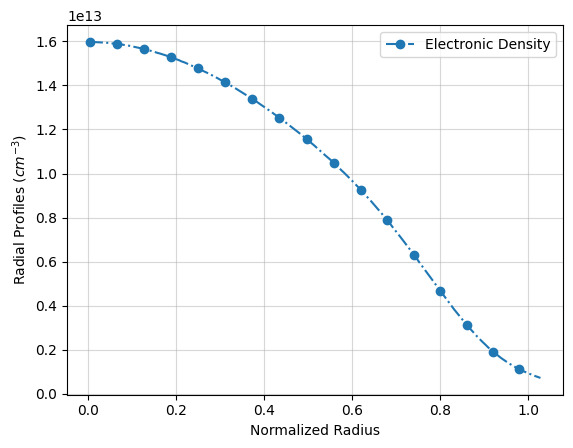

In [29]:
#plt.plot(df["raio[m]_normal"], df[" Te[kev]"]/df[" Te[kev]"].max(), ls = "--", marker = "^", markevery = 10,label = "Electronic Temperature")
plt.plot(df["raio[m]_normal"], df[" Ni[x10^19m^-1]"]*1e-6, ls = "-.",marker = "o", markevery = 10, label = "Electronic Density")
plt.xlabel(f"Normalized Radius")
plt.ylabel("Radial Profiles ($cm^{-3}$)")
plt.grid(True, which = "both", alpha = .5)
plt.legend()
plt.savefig("graphs/electronic_radial_Density_profile.png")
plt.show()

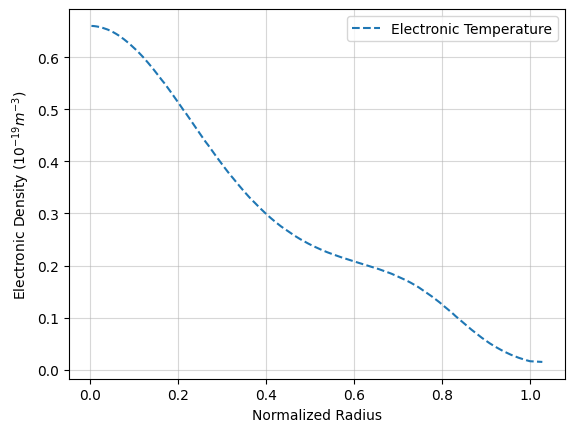

In [11]:
plt.plot(df["raio[m]_normal"], df[" Te[kev]"]*1e-3, ls = "--", label = "Electronic Temperature")
plt.grid(True, which = "both", alpha = .5)
plt.xlabel(f"Normalized Radius")
plt.ylabel("Electronic Density ($10^{{-19}}m^{{-3}}$)")
plt.legend()
plt.savefig("graphs/temperature_radial_profile.png")
plt.show()

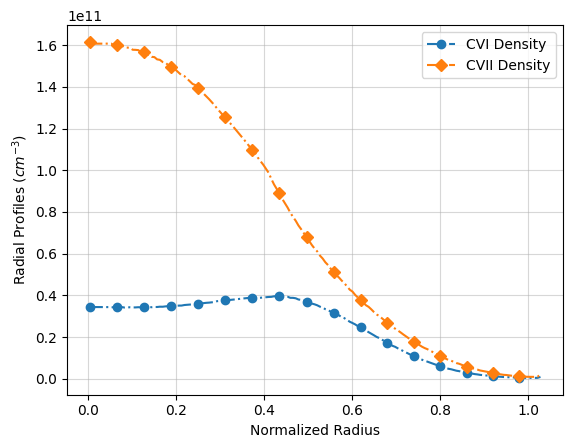

In [12]:
plt.plot(df["raio[m]_normal"], df[" c^+5[m^-3]"]*1e-6, ls = "-.", marker = "o", markevery = 10,label = "CVI Density")
plt.plot(df["raio[m]_normal"], df[" c^+6[m^-3]"]*1e-6, ls = "-.", marker = "D", markevery = 10,label = "CVII Density")
plt.grid(True, which = "both", alpha = .5)
plt.xlabel(f"Normalized Radius")
plt.ylabel("Radial Profiles ($cm^{-3}$)")
plt.legend()
plt.savefig("graphs/carbon_ions_radial_profile.png")
plt.show()

In [13]:
df.head()

,raio[m],Nz[m^-3],c^+5[m^-3],c^+6[m^-3],Te[kev],Ti[kev],Ne[x10^19m^-1],Ni[x10^19m^-1],raio_y,density_n,raio[m]_normal,PECS Excit,PECS Recomb
0,0.000554,2.000000e+17,3.451860e+16,1.615500e+17,660.2,212.0,2.000000e+19,1.597400e+19,NaN,NaN,0.003078,3.2612731164146317e-13,3.62793447832569e-16
1,0.001600,1.990000e+17,3.437890e+16,1.607060e+17,659.9,211.9,1.999000e+19,1.596600e+19,0.002,1.301640e+15,0.008889,3.260611797944958e-13,3.6303241520970877e-16
2,0.002700,1.990000e+17,3.437890e+16,1.607060e+17,659.2,211.8,1.999000e+19,1.596600e+19,0.003,1.303290e+15,0.015000,3.25900308913075e-13,3.6359072162353197e-16
3,0.003800,1.990000e+17,3.437820e+16,1.607030e+17,658.2,211.7,1.998000e+19,1.595800e+19,0.004,1.304950e+15,0.021111,3.256729522432931e-13,3.6438919940808107e-16
4,0.004900,1.990000e+17,3.437820e+16,1.607030e+17,656.9,211.5,1.997000e+19,1.595400e+19,0.005,1.306630e+15,0.027222,3.2537603160867034e-13,3.65429067457783e-16


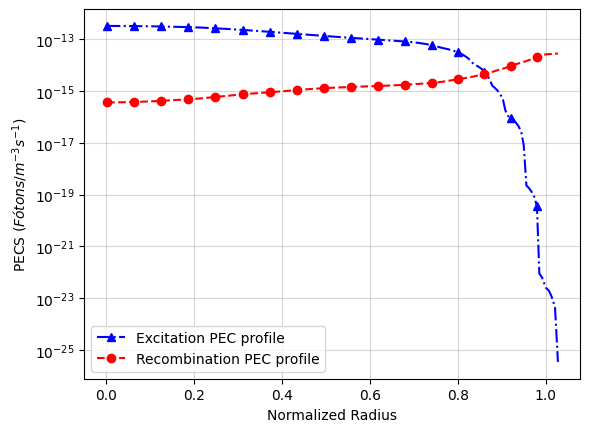

In [14]:
plt.plot(df["raio[m]_normal"], df["PECS Excit"], ls = "-.", marker = "^", markevery = 10 ,color = "b",label = "Excitation PEC profile")
plt.plot(df["raio[m]_normal"], df["PECS Recomb"], ls = "--",  marker = "o", markevery = 10,color = "r", label = "Recombination PEC profile")
plt.yscale("log")
plt.grid(True, which = "both", alpha = .5)
plt.xlabel(f"Normalized Radius")
plt.ylabel("PECS $(Fótons/m^{-3}s^{-1})$")
plt.legend()
plt.savefig("graphs/PEC_radial_profile.png")
plt.show()

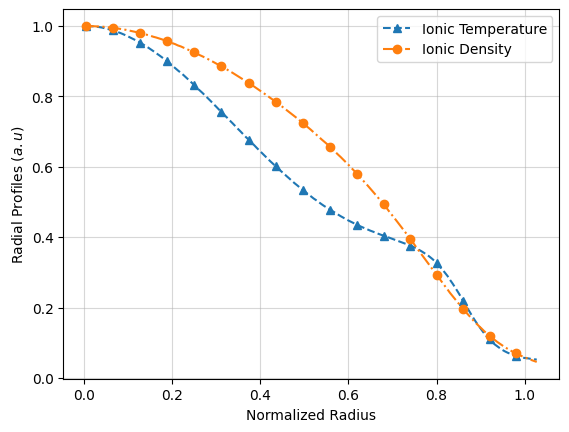

In [15]:
plt.plot(df["raio[m]_normal"], df[" Ti[kev]"]/df[" Ti[kev]"].max(), ls = "--", marker = "^", markevery = 10, label = "Ionic Temperature")
plt.plot(df["raio[m]_normal"], df[" Ni[x10^19m^-1]"]/df[" Ni[x10^19m^-1]"].max(), ls = "-.", marker = "o", markevery = 10,label = "Ionic Density")
plt.grid(True, which = "both", alpha = .5)
plt.xlabel(f"Normalized Radius")
plt.ylabel("Radial Profiles ($a.u$)")
plt.legend()
plt.savefig("graphs/ion_temperature_radial_profile.png")
plt.show()

In [16]:
# Calculating the fractial abundances for CVI e CV:

partial_abundances = np.zeros((carbon.atomic_number + 1, len(df.iloc[:,0])))
for idx,t_val in enumerate(df.iloc[:,0]):
    partial_abundances[:, idx] = solve_ion_balance(carbon, n_e = df[" Ne[x10^19m^-1]"][idx], t_e = df[" Te[kev]"][idx], coef_ion = ionisation_rates, coef_recom = recombination_rates)

df["fa_c5"] = partial_abundances[5]
df["fa_c6"] = partial_abundances[6]

In [17]:
#df["n_c5_eff"] = df["fa_c5"]*df[" Nz[m^-3]"]
#df["n_c6_eff"] = df["fa_c6"]*df[" Nz[m^-3]"]
df["n_c5_eff"] = df[' c^+5[m^-3]']
df["n_c6_eff"] = df[' c^+6[m^-3]']
#df["n_c5_eff"] = df["fa_c5"]*df[' c^+5[m^-3]']
#df["n_c6_eff"] = df["fa_c6"]*df[' c^+6[m^-3]']

# emissivity = []
# for idx in range(len(df.iloc[:,0])):
#     emissivity.append(get_emissivity(ne= df[" Ne[x10^19m^-1]"][idx], te = df[" Te[kev]"][idx], n_c5_eff = df["n_c5_eff"][idx], n_c6_eff = df["n_c6_eff"][idx], n0=df['density_n'][idx], energy = 5e3, Zeff = 1, B0 = 1.1, ti = df[' Ti[kev]'][idx]))

emissivity = []
for idx in range(len(df.iloc[:,0])):
    emissivity.append(get_emissivity(ne= df[" Ne[x10^19m^-1]"][idx], te = df[" Te[kev]"][idx], n_c5_eff = df["n_c5_eff"][idx], n_c6_eff = df["n_c6_eff"][idx]))# n0=df['density_n'][idx], energy = 5e3, Zeff = 1, B0 = 1.1, ti = df[' Ti[kev]'][idx]))

df["emissivity"] = emissivity

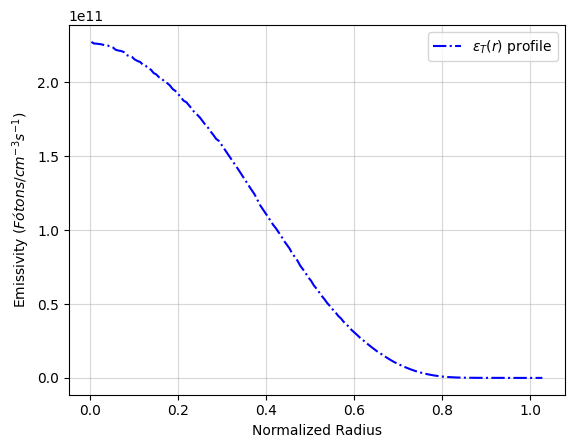

In [18]:
plt.plot(df["raio[m]_normal"], df["emissivity"]*1e-6, ls = "-.", color = "b",label = r"$\varepsilon_T (r)$ profile")
plt.grid(True, which = "both", alpha = .5)
plt.xlabel(f"Normalized Radius")
plt.ylabel("Emissivity $(Fótons/cm^{-3}s^{-1})$")
plt.legend()
plt.savefig("graphs/Emissivity_radial_profile.png")
plt.show()

In [19]:
def get_emissivity(ne, te, n_c5_eff, n_c6_eff, n0=None):
    
    pec_excit_adas = adas.impact_excitation_pec(carbon, 5, (8, 7)) #
    pec_recomb_adas = adas.recombination_pec(carbon, 5, (8, 7))
    #pec_cx_adas = adas.
    
    wavelength = 529.97e-9  # meters
    e_photon = (h * c) / wavelength # SI units
    
    conv_factor = e_photon  
    
    emissivity_excit = n_c5_eff * (pec_excit_adas(ne, te)/ conv_factor)
    emissivity_recomb = n_c6_eff * (pec_recomb_adas(ne, te)/ conv_factor)
    
    total_rate = emissivity_excit #+ emissivity_recomb
    
    if n0 is not None:
        pec_cx_adas = adas.charge_exchange_pec(carbon, 5, (8, 7))
        emissivity_cx = (n0 / ne) * n_c6_eff * pec_cx_adas(ne, te)
        total_rate += emissivity_cx

    return ne * total_rate 

In [20]:
emissivity_excita = []
for idx in range(len(df.iloc[:,0])):
    emissivity_excita.append(get_emissivity(ne= df[" Ne[x10^19m^-1]"][idx], te = df[" Te[kev]"][idx], n_c5_eff = df["n_c5_eff"][idx], n_c6_eff = df["n_c6_eff"][idx] , n0 = None))

df["emissivity_excitation"] = emissivity_excita

In [21]:
def get_emissivity(ne, te, n_c5_eff, n_c6_eff, n0=None):
    
    pec_excit_adas = adas.impact_excitation_pec(carbon, 5, (8, 7))
    pec_recomb_adas = adas.recombination_pec(carbon, 5, (8, 7))
    
    wavelength = 529.97e-9  # meters
    e_photon = (h * c) / wavelength #SI
    
    conv_factor = e_photon  #
    
    emissivity_excit = n_c5_eff * (pec_excit_adas(ne, te)/ conv_factor)
    emissivity_recomb = n_c6_eff * (pec_recomb_adas(ne, te)/ conv_factor)
    
    total_rate = emissivity_recomb #+ emissivity_excit 
    
    if n0 is not None:
        pec_cx_adas = adas.beam_cx_pec(carbon, 5, (8, 7))
        emissivity_cx = (n0 / ne) * n_c6_eff * pec_cx_adas(ne, te)
        total_rate += emissivity_cx

    return ne * total_rate 

In [22]:
emissivity_recomb = []
for idx in range(len(df.iloc[:,0])):
    emissivity_recomb.append(get_emissivity(ne= df[" Ne[x10^19m^-1]"][idx], te = df[" Te[kev]"][idx], n_c5_eff = df["n_c5_eff"][idx], n_c6_eff = df["n_c6_eff"][idx] , n0 = None))

df["emissivity_recombination"] = emissivity_recomb

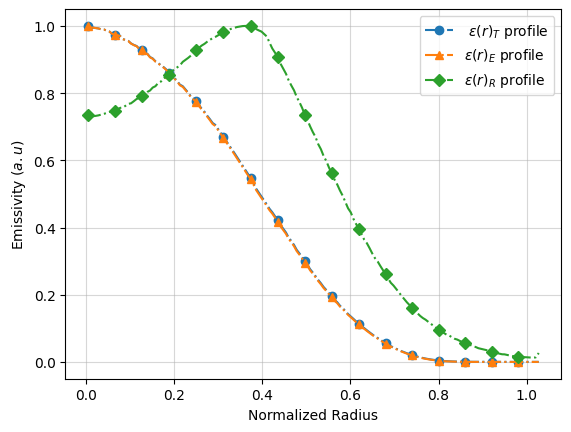

In [23]:
plt.plot(df["raio[m]_normal"], df["emissivity"]/df["emissivity"].max(),color = "C0", ls = "-.", marker = "o", markevery = 10,label = r" ${\varepsilon (r)}_{T}$ profile")
plt.plot(df["raio[m]_normal"], df["emissivity_excitation"]/df["emissivity_excitation"].max(),color = "C1", ls = "-.", marker = "^", markevery = 10,label = r"${\varepsilon (r)}_{E}$ profile")
plt.plot(df["raio[m]_normal"], df["emissivity_recombination"]/df["emissivity_recombination"].max(),color = "C2", ls = "-.", marker = "D", markevery = 10,label = r"${\varepsilon (r)}_{R}$ profile")
#plt.plot(df["raio[m]_normal"], df["emissivity_cx"]/df["emissivity_cx"].max(), color = "C3",ls = "-.", marker = "*", markevery = 10,label = r"${\varepsilon (r)}_{cx}$ profile")
plt.grid(True, which = "both", alpha = .5)
plt.xlabel(f"Normalized Radius")
plt.ylabel("Emissivity $(a.u)$")
plt.legend()
plt.savefig("graphs/Emissivity_radial_normalizado_certo.png")
plt.show()

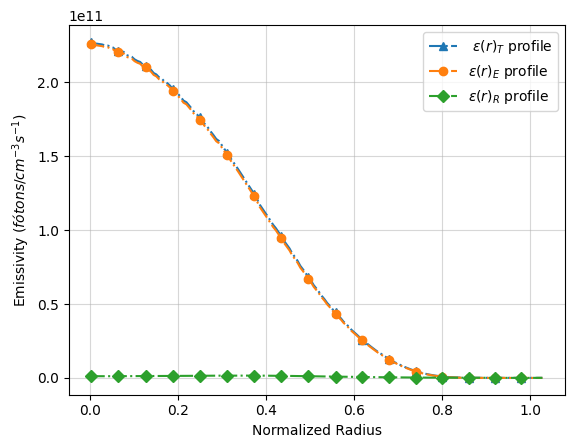

In [24]:
plt.plot(df["raio[m]_normal"], df["emissivity"]*1e-6, ls = "-.",color = "C0",  marker = "^", markevery = 10,label = r" ${\varepsilon (r)}_{T}$ profile")
plt.plot(df["raio[m]_normal"], df["emissivity_excitation"]*1e-6, ls = "-.",color = "C1", marker = "o", markevery = 10,label = r"${\varepsilon (r)}_{E}$ profile")
plt.plot(df["raio[m]_normal"], df["emissivity_recombination"]*1e-6, ls = "-.",color = "C2", marker = "D", markevery = 10,label = r"${\varepsilon (r)}_{R}$ profile")
#plt.plot(df["raio[m]_normal"], df["emissivity_cx"]*1e-6, color = "C3",ls = "-.", marker = "*", markevery = 10,label = r"${\varepsilon (r)}_{cx}$ profile")
plt.grid(True, which = "both", alpha = .5)
plt.xlabel(f"Normalized Radius")
plt.ylabel("Emissivity $(fótons/cm^{-3}s^{-1})$")
plt.legend()
plt.savefig("graphs/Emissivity_radial_certo_comparaçao.png")
plt.show()

In [28]:
df["emissivity"].to_csv("emissivity.csv")

In [26]:
df.head()

,raio[m],Nz[m^-3],c^+5[m^-3],c^+6[m^-3],Te[kev],Ti[kev],Ne[x10^19m^-1],Ni[x10^19m^-1],raio_y,density_n,raio[m]_normal,PECS Excit,PECS Recomb,fa_c5,fa_c6,n_c5_eff,n_c6_eff,emissivity,emissivity_excitation,emissivity_recombination
0,0.000554,2.000000e+17,3.451860e+16,1.615500e+17,660.2,212.0,2.000000e+19,1.597400e+19,NaN,NaN,0.003078,3.2612731164146317e-13,3.62793447832569e-16,0.002834,0.997157,3.451860e+16,1.615500e+17,2.274598e+17,2.263024e+17,1.157407e+15
1,0.001600,1.990000e+17,3.437890e+16,1.607060e+17,659.9,211.9,1.999000e+19,1.596600e+19,0.002,1.301640e+15,0.008889,3.260611797944958e-13,3.6303241520970877e-16,0.002836,0.997155,3.437890e+16,1.607060e+17,2.263858e+17,2.252344e+17,1.151452e+15
2,0.002700,1.990000e+17,3.437890e+16,1.607060e+17,659.2,211.8,1.999000e+19,1.596600e+19,0.003,1.303290e+15,0.015000,3.25900308913075e-13,3.6359072162353197e-16,0.002842,0.997150,3.437890e+16,1.607060e+17,2.262904e+17,2.251374e+17,1.153011e+15
3,0.003800,1.990000e+17,3.437820e+16,1.607030e+17,658.2,211.7,1.998000e+19,1.595800e+19,0.004,1.304950e+15,0.021111,3.256729522432931e-13,3.6438919940808107e-16,0.002849,0.997142,3.437820e+16,1.607030e+17,2.260380e+17,2.248834e+17,1.154645e+15
4,0.004900,1.990000e+17,3.437820e+16,1.607030e+17,656.9,211.5,1.997000e+19,1.595400e+19,0.005,1.306630e+15,0.027222,3.2537603160867034e-13,3.65429067457783e-16,0.002860,0.997132,3.437820e+16,1.607030e+17,2.257489e+17,2.245920e+17,1.156979e+15


In [27]:
# plt.plot(df["raio[m]_normal"], df["emissivity"]*1e-6,color = "C0", ls = "-.",  marker = "^", markevery = 10,label = r" ${\varepsilon (r)}_{T}$ profile")
# plt.plot(df["raio[m]_normal"], df["emissivity_excitation"]*1e-6,color = "C1" ,ls = "-.", marker = "o", markevery = 10,label = r"${\varepsilon (r)}_{E}$ profile")
# plt.plot(df["raio[m]_normal"], df["emissivity_recombination"]*1e-6,color = "C2", ls = "-.", marker = "D", markevery = 10,label = r"${\varepsilon (r)}_{R}$ profile")
# plt.plot(df["raio[m]_normal"], df["emissivity_cx"]*1e-6, color = "C3",ls = "-.", marker = "*", markevery = 10,label = r"${\varepsilon (r)}_{cx}$ profile")
# plt.grid(True, which = "both", alpha = .5)
# plt.xlabel(f"Normalized Radius")
# plt.ylabel("Emissivity $(fótons/cm^{-3}s^{-1})$")
# plt.xlim(.8,1.0)
# plt.ylim(-1e7,.5e9)
# plt.legend(loc="center")
# plt.savefig("graphs/Emissivity_radial_profile_region_certo_cx.png")
# plt.show()